# Tutorial 3 — dataset6 (Stereo-seq): organs of the mouse embryo

Two sections of the Stereo-seq mouse organogenesis atlas (MOSTA; Chen *et al.*, *Cell* 2022) from dataset6.

In [1]:
import sys
sys.path.insert(0, "../src")

import hashlib
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import cosmim
import os, urllib.request
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

## 1. Download

In [2]:
FILES = {"E10.5_E1S1": "c4c61b80c310da5ce1437ea826ba4706",
         "E10.5_E2S1": "ac9c547b59a7ba3b0f4bd2c0cc5057b9"}
# URL = "http://sdmbench.drai.cn/tcm/download/?file_path=/mnt/JINGD/data/file/sdmbench/db/{}.MOSTA.h5ad"
# for name, md5 in FILES.items():
#     path = f"../data/D6_StereoSeq/{name}.MOSTA.h5ad"
#     if not os.path.exists(path):
#         urllib.request.urlretrieve(URL.format(name), path)
#     assert hashlib.md5(open(path, "rb").read()).hexdigest() == md5, name

## 2. CoSMIM on both sections

In [3]:
results = {}
for name in FILES:
    knn = np.load(f"../figures/fig4/neighbours_{name}.npz")["neighbours"]
    results[name] = cosmim.run(sc.read_h5ad(f"../data/D6_StereoSeq/{name}.MOSTA.h5ad"), annotation_key="annotation", strategy="svg_hvg", n_top_hvg=256, n_pcs=30, n_neighbors=150, knn=knn)
    r = results[name]
    print(name, r.n_obs, "cells,", r.obs["annotation"].nunique(), "organs,", r.obs["cosmim"].nunique(), "clusters, NMI", round(r.uns["cosmim"]["NMI"], 4))

find_resolution: no resolution gives 13 clusters; using 0.4000, which is 1 away


E10.5_E1S1 18404 cells, 13 organs, 14 clusters, NMI 0.5586


E10.5_E2S1 8494 cells, 18 organs, 18 clusters, NMI 0.6013


### The competitors

The clusters of NichePCA, BANKSY, COVET and PCA+Leiden on both sections.

In [4]:
#   pip install nichepca==0.1.0 pybanksy==1.3.4 scenvi==0.4.6 jax==0.4.29
#
# import anndata as ad
# import banksy.run_banksy as banksy_run
# import nichepca as npc
# from banksy.initialize_banksy import initialize_banksy
# from scenvi.utils import compute_covet
#
# def leiden_to(adata, n, seed=1234):
#     """Leiden with n clusters on the existing graph."""
#     res = cosmim.find_resolution(adata, n, random_state=seed)
#     sc.tl.leiden(adata, resolution=res, random_state=seed, flavor="igraph", n_iterations=2)
#     return adata.obs["leiden"].values
#
# def run_competitors(adata, annotation_key, n_hvg=64, seed=1234):
#     """Clusters of NichePCA (k=15), BANKSY (k=20), COVET (k=8) and PCA+Leiden (30 PCs)."""
#     raw, hvg = cosmim.spatial_preprocess_pipeline(adata, strategy="svg_hvg", n_top_hvg=n_hvg)
#     n = cosmim.get_num_groups(raw, annotation_key)
#     out = pd.DataFrame(index=raw.obs_names)
#
#     a = raw.copy()                                        # NichePCA
#     npc.wf.nichepca(a, knn=15, n_comps=8)
#     sc.pp.neighbors(a, use_rep="X_npca", n_neighbors=15, random_state=seed)
#     out["NichePCA"] = leiden_to(a, n)
#
#     a = raw.copy()                                        # BANKSY
#     a.obs["x"], a.obs["y"] = a.obsm["spatial"][:, 0], a.obsm["spatial"][:, 1]
#     params = initialize_banksy(a, coord_keys=("x", "y", "spatial"), num_neighbours=20,
#                                nbr_weight_decay="scaled_gaussian", max_m=1,
#                                plt_edge_hist=False, plt_nbr_weights=False)
#     banksy_run.subplot_sc = lambda *args, **kwargs: None
#     result = banksy_run.run_banksy_multiparam(
#         a, params, lambda_list=[0.8], resolutions=[], max_m=1, pca_dims=[15],
#         color_list=list(plt.cm.tab20.colors) * 10, filepath="banksy_tmp",
#         key=("scaled_gaussian",), savefig=False, add_nonspatial=False, annotation_key=None,
#         max_labels=n, cluster_algorithm="leiden", partition_seed=seed)
#     out["BANKSY"] = result.iloc[-1]["labels"].dense
#
#     h = hvg.copy()                                        # COVET, on the same genes
#     h.X = h.X.toarray() if hasattr(h.X, "toarray") else h.X
#     _, covet_sqrt, _ = compute_covet(h, k=8, g=h.n_vars)
#     f = ad.AnnData(X=covet_sqrt.reshape(len(h), -1).astype(np.float32))
#     sc.pp.pca(f, n_comps=30, random_state=seed)
#     sc.pp.neighbors(f, n_neighbors=50, n_pcs=30, random_state=seed)
#     out["COVET"] = leiden_to(f, n)
#
#     x = hvg.X.toarray() if hasattr(hvg.X, "toarray") else hvg.X   # PCA + Leiden
#     f = ad.AnnData(X=np.asarray(x, dtype=np.float32))
#     sc.pp.pca(f, n_comps=30, random_state=seed)
#     sc.pp.neighbors(f, n_neighbors=50, n_pcs=30, use_rep="X_pca", random_state=seed)
#     out["PCA+Leiden"] = leiden_to(f, n)
#     return out
#
# for name in FILES:
#     run_competitors(sc.read_h5ad(f"../data/D6_StereoSeq/{name}.MOSTA.h5ad"), "annotation").to_csv(
#         f"../figures/fig4/competitors_{name}.csv")

In [5]:
labels = {}
for name, r in results.items():
    comp = pd.read_csv(f"../figures/fig4/competitors_{name}.csv", index_col=0).astype(str)
    labels[name] = pd.DataFrame({"CoSMIM": r.obs["cosmim"].astype(str).values},
                                index=r.obs_names).join(comp.loc[r.obs_names])

## Recovering the brain and the liver

For each organ, the cluster of each method with the largest intersection over union (IoU) with the annotated organ. An IoU below 0.3 counts as not resolved.

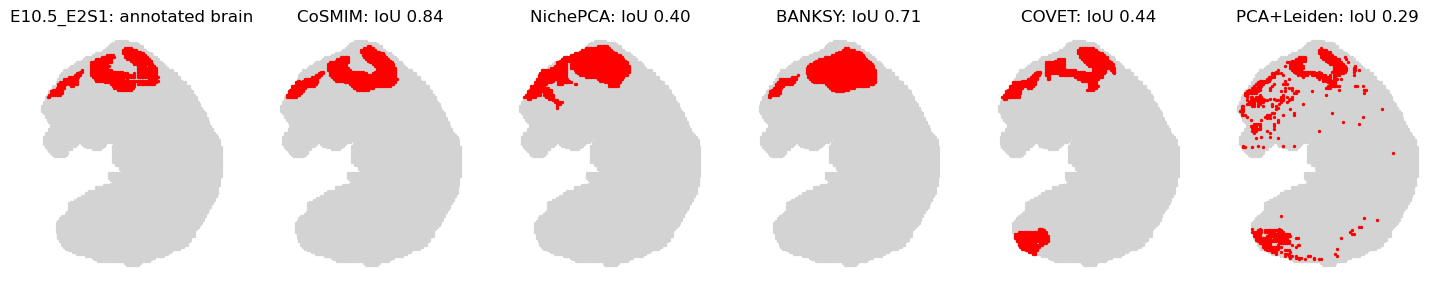

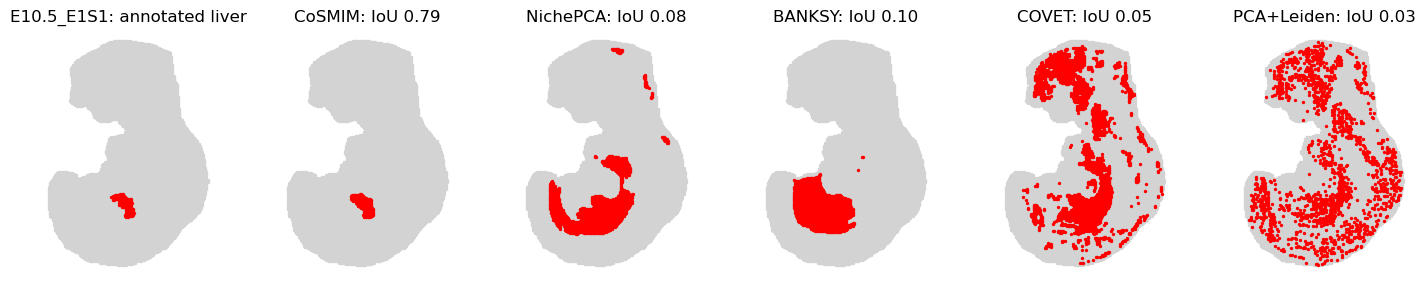

,BANKSY,COVET,CoSMIM,NichePCA,PCA+Leiden
Brain,0.7106,0.4389,0.8395,0.3964,0.2860
Liver,0.1006,0.0538,0.7854,0.0817,0.0304


In [6]:
def best_cluster(truth, pred, organ):
    """The cluster with the largest IoU with the organ, and that IoU."""
    iou = {c: ((truth == organ) & (pred == c)).sum() / ((truth == organ) | (pred == c)).sum()
           for c in np.unique(pred)}
    best = max(iou, key=iou.get)
    return best, iou[best]


iou_table = {}
for name, organ in [("E10.5_E2S1", "Brain"), ("E10.5_E1S1", "Liver")]:
    r = results[name]
    xy, truth = r.obsm["spatial"], r.obs["annotation"].astype(str).values
    fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
    axes[0].scatter(xy[:, 0], xy[:, 1], s=2, c="lightgrey")
    axes[0].scatter(xy[truth == organ, 0], xy[truth == organ, 1], s=2, c="red")
    axes[0].set_title(f"{name}: annotated {organ.lower()}")
    for ax, method in zip(axes[1:], labels[name].columns):
        best, iou = best_cluster(truth, labels[name][method].values, organ)
        iou_table[(organ, method)] = iou
        cells = labels[name][method].values == best
        ax.scatter(xy[:, 0], xy[:, 1], s=2, c="lightgrey")
        ax.scatter(xy[cells, 0], xy[cells, 1], s=2, c="red")
        ax.set_title(f"{method}: IoU {iou:.2f}")
    for ax in axes:
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
    plt.show()
pd.Series(iou_table).unstack().round(4)

## What a differential expression test finds

A Wilcoxon test of the liver against all other cells of `E10.5_E1S1` returns the canonical hepatoblast markers. The test needs the region as input; it does not find the region.

{'Afp': 1, 'Apoa2': 2, 'Rbp4': 3, 'Ttr': 9, 'Fgb': 17}


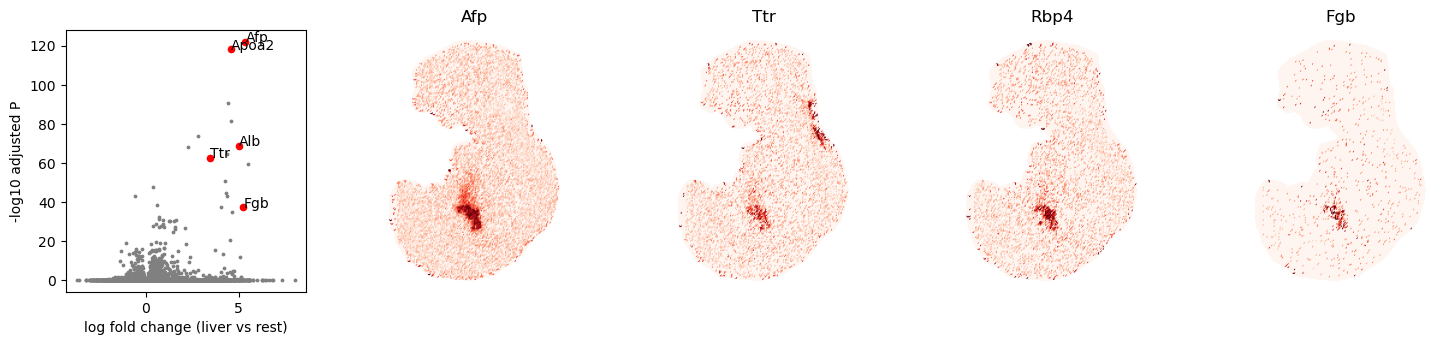

In [7]:
a1 = results["E10.5_E1S1"]
sc.tl.rank_genes_groups(a1, "annotation", groups=["Liver"], reference="rest",
                        method="wilcoxon", n_genes=a1.n_vars)
de = sc.get.rank_genes_groups_df(a1, group="Liver")
print({g: int(np.where(de["names"] == g)[0][0]) + 1 for g in ["Afp", "Apoa2", "Rbp4", "Ttr", "Fgb"]})

fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
shown = de[de["logfoldchanges"] > -10]
y = -np.log10(np.clip(shown["pvals_adj"], 1e-300, None))
axes[0].scatter(shown["logfoldchanges"], y, s=3, c="grey")
for g in ["Afp", "Apoa2", "Alb", "Ttr", "Fgb"]:
    i = shown.index[shown["names"] == g][0]
    axes[0].scatter(shown.loc[i, "logfoldchanges"], y[i], s=20, c="red")
    axes[0].annotate(g, (shown.loc[i, "logfoldchanges"], y[i]))
axes[0].set_xlabel("log fold change (liver vs rest)")
axes[0].set_ylabel("-log10 adjusted P")
for ax, g in zip(axes[1:], ["Afp", "Ttr", "Rbp4", "Fgb"]):
    values = a1[:, g].X.toarray().ravel()
    ax.scatter(a1.obsm["spatial"][:, 0], a1.obsm["spatial"][:, 1], c=values, s=1, cmap="Reds",
               vmax=np.percentile(values, 99.8))
    ax.set_title(g)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
plt.show()

## Same mean, different covariance

The domain matrices are computed as in the paper and each domain's correlation matrix is the mean niche covariance of a stratified subsample of its cells.

Left: one gene pair in the liver and in the domain where the same pair correlates least.
Right: for each other domain, its similarity to the liver by mean expression profile and by niche correlation matrix.

Thbs1-Grhl3: Liver 0.95472 | Spinal cord 0.01271
median r: mean profile 0.9232  covariance 0.2137


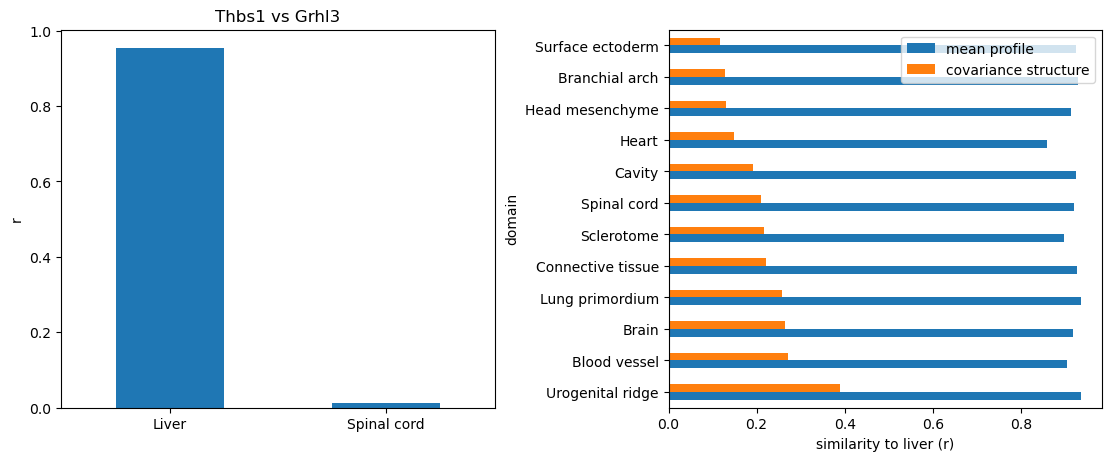

In [8]:
def niche_sigma(features):
    """Niche covariance of each cell, S @ S."""
    g = int((np.sqrt(8 * features.shape[1] + 1) - 1) / 2)
    S = cosmim.from_tril(np.asarray(features, dtype=np.float64), g)
    return np.einsum("nij,njk->nik", S, S)


def to_corr(cov):
    sd = np.sqrt(np.clip(np.diag(cov), 1e-12, None))
    return cov / np.outer(sd, sd)


def stratified_domain_correlations(features, domains, chunk=1500, max_entries=4e8):
    """Domain correlation matrices from a stratified subsample of cells (as in the paper)."""
    g = int((np.sqrt(8 * features.shape[1] + 1) - 1) / 2)
    n = len(domains)
    cap = max(800, int(max_entries / (g * g)))
    if n > cap:
        rng = np.random.RandomState(0)
        per = max(60, cap // max(1, len(set(domains))))
        keep = np.sort(np.concatenate([rng.permutation(np.where(domains == d)[0])[:per]
                                       for d in sorted(set(domains))]))
    else:
        keep = np.arange(n)
    sums, counts = {}, {}
    for start in range(0, n, chunk):
        sel = keep[(keep >= start) & (keep < start + chunk)]
        if not len(sel):
            continue
        sigma = niche_sigma(features[sel])
        for d in set(domains[sel]):
            m = domains[sel] == d
            sums[d] = sums.get(d, 0) + sigma[m].sum(0)
            counts[d] = counts.get(d, 0) + int(m.sum())
    return {d: to_corr(sums[d] / counts[d]) for d in sorted(sums) if d.lower() != "nan"}


run_genes = open("../figures/fig4/selected_genes.txt").read().split("\n")[1:-1]
domains1 = a1.obs["annotation"].astype(str).values
corr = stratified_domain_correlations(a1.obsm["cosmim"], domains1)

i, j = run_genes.index("Thbs1"), run_genes.index("Grhl3")
pair = {d: corr[d][i, j] for d in corr}
other = min((d for d in pair if d != "Liver"), key=lambda d: abs(pair[d]))

keep = [(k, g) for k, g in enumerate(run_genes) if g in a1.var_names]
sub = [k for k, _ in keep]
X = a1.X.toarray() if hasattr(a1.X, "toarray") else np.asarray(a1.X)
Xg = X[:, [a1.var_names.get_loc(g) for _, g in keep]]
iu_sub = np.triu_indices(len(sub), k=1)
liver_vec = corr["Liver"][np.ix_(sub, sub)][iu_sub]
rows = []
for d in corr:
    if d == "Liver":
        continue
    r_mean = np.corrcoef(Xg[domains1 == "Liver"].mean(0), Xg[domains1 == d].mean(0))[0, 1]
    vec = corr[d][np.ix_(sub, sub)][iu_sub]
    ok = np.isfinite(liver_vec) & np.isfinite(vec)
    rows.append((d, r_mean, np.corrcoef(liver_vec[ok], vec[ok])[0, 1]))
similarity = pd.DataFrame(rows, columns=["domain", "r_mean", "r_cov"]).sort_values("r_cov", ascending=False)
print("Thbs1-Grhl3: Liver", round(pair["Liver"], 5), "|", other, round(pair[other], 5))
print("median r: mean profile", round(similarity["r_mean"].median(), 4),
      " covariance", round(similarity["r_cov"].median(), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
pd.Series({"Liver": pair["Liver"], other: pair[other]}).plot.bar(ax=axes[0], rot=0)
axes[0].set_ylabel("r")
axes[0].set_title("Thbs1 vs Grhl3")
similarity.set_index("domain")[["r_mean", "r_cov"]].plot.barh(ax=axes[1])
axes[1].set_xlabel("similarity to liver (r)")
axes[1].legend(["mean profile", "covariance structure"])
plt.show()

## The liver matrix is reproducible

The liver cells are split into two random halves five times; the correlation between the two halves' matrices is compared with the median correlation between the liver matrix and the matrices of the other domains. 

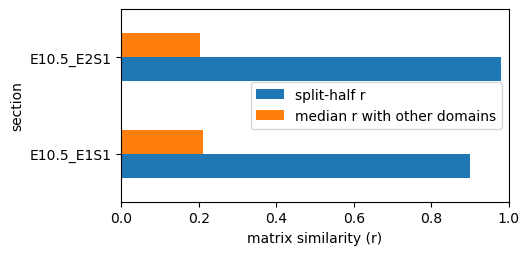

,split-half r,median r with other domains
section,,
E10.5_E1S1,0.901,0.212
E10.5_E2S1,0.980,0.204


In [9]:
def domain_correlations(features, domains, chunk=1000):
    """Domain correlation matrices from all cells."""
    sums, counts = {}, {}
    for start in range(0, len(domains), chunk):
        sigma = niche_sigma(features[start:start + chunk])
        part = domains[start:start + chunk]
        for d in set(part):
            sums[d] = sums.get(d, 0) + sigma[part == d].sum(0)
            counts[d] = counts.get(d, 0) + int((part == d).sum())
    return {d: to_corr(sums[d] / counts[d]) for d in sorted(sums) if d.lower() != "nan"}


def split_half(features, cells, rng, repeats=5):
    """Mean r between the matrices of two random halves of `cells`."""
    sigma = niche_sigma(features[cells]).astype(np.float32)
    iu = np.triu_indices(sigma.shape[1], k=1)
    m = len(cells)
    rs = []
    for _ in range(repeats):
        sel = rng.permutation(m)
        a, b = sel[:m // 2], sel[m // 2:2 * (m // 2)]
        ca = to_corr(sigma[a].mean(0).astype(np.float64))[iu]
        cb = to_corr(sigma[b].mean(0).astype(np.float64))[iu]
        ok = np.isfinite(ca) & np.isfinite(cb)
        rs.append(np.corrcoef(ca[ok], cb[ok])[0, 1])
    return float(np.mean(rs))


rows = []
for name in FILES:
    r = results[name]
    truth = r.obs["annotation"].astype(str).values
    matrices = domain_correlations(r.obsm["cosmim"], truth)
    iu = np.triu_indices(len(matrices["Liver"]), k=1)
    cross = np.median([np.corrcoef(matrices["Liver"][iu], m[iu])[0, 1]
                       for d, m in matrices.items() if d != "Liver"])
    half = split_half(r.obsm["cosmim"], np.where(truth == "Liver")[0], np.random.RandomState(0))
    rows.append({"section": name, "split-half r": half, "median r with other domains": cross})
reliability = pd.DataFrame(rows).set_index("section")
reliability.plot.barh(figsize=(5, 2.5), xlim=(0, 1), xlabel="matrix similarity (r)")
plt.show()
reliability.round(3)

## The liver niche covariance over 21 genes

Upper: the liver matrices of CoSMIM (from the domain matrices above) and of COVET. Lower: in each domain, the mean correlation within the liver block (CORE) and within the set of genes that the same clustering returns in at least eight of the twelve other domains.

shared set: [np.str_('Ccdc50'), np.str_('Clasp1'), np.str_('Ctnna3'), np.str_('Fam162a'), np.str_('Frmd4b'), np.str_('Ifitm1'), np.str_('Myl7'), np.str_('Nudcd2'), np.str_('Nxn'), np.str_('Rnf7'), np.str_('Rpl26'), np.str_('Tra2b')]


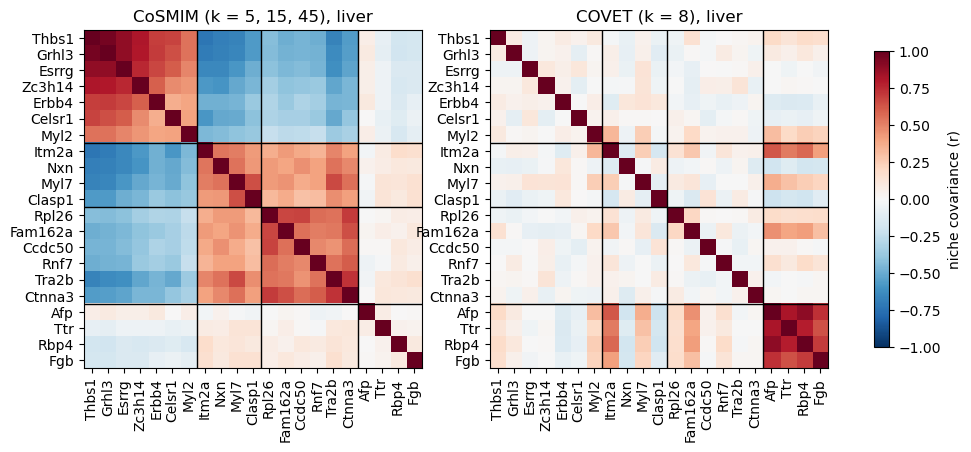

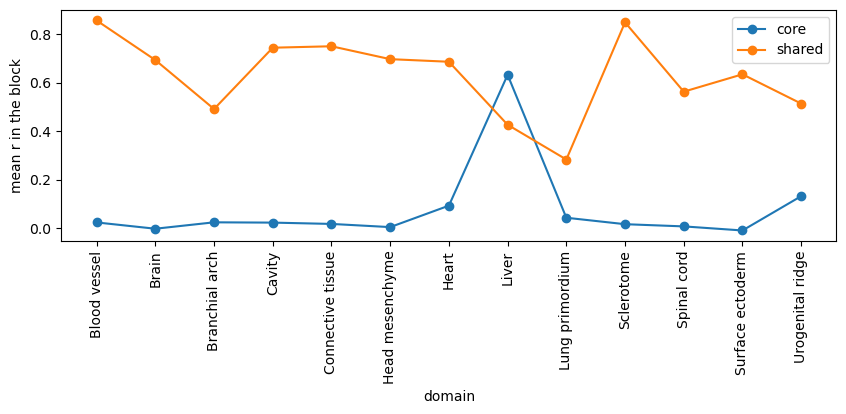

,core,shared
domain,,
Blood vessel,0.024,0.858
Brain,-0.001,0.694
Branchial arch,0.025,0.492
Cavity,0.024,0.745
Connective tissue,0.018,0.751
Head mesenchyme,0.005,0.698
Heart,0.094,0.687
Liver,0.633,0.427
Lung primordium,0.044,0.284


In [10]:
BLOCKS = {"core": ["Thbs1", "Grhl3", "Esrrg", "Zc3h14", "Erbb4", "Celsr1", "Myl2"],
          "anti": ["Itm2a", "Nxn", "Myl7", "Clasp1"],
          "nonspec": ["Rpl26", "Fam162a", "Ccdc50", "Rnf7", "Tra2b", "Ctnna3"],
          "marker": ["Afp", "Ttr", "Rbp4", "Fgb"]}
panel_genes = [g for block in BLOCKS.values() for g in block if g in run_genes]

covet = sc.read_h5ad("../figures/fig4/covet_E10.5_E1S1_panel_genes.h5ad")
assert list(covet.uns["genes"]) == panel_genes and (covet.obs_names == a1.obs_names).all()
covet_cells = cosmim.from_tril(np.asarray(covet.X), len(panel_genes))
liver = domains1 == "Liver"

idx = [run_genes.index(g) for g in panel_genes]
cosmim_liver = pd.DataFrame(corr["Liver"][np.ix_(idx, idx)], index=panel_genes, columns=panel_genes)
mean_liver = covet_cells[liver].mean(0).astype(np.float64)
covet_liver = pd.DataFrame(np.clip(to_corr(mean_liver), -1, 1), index=panel_genes, columns=panel_genes)


def tightest_block(M, cut=0.55):
    """The cluster of at least 3 genes with the highest mean r (average linkage on 1 - r)."""
    M = M.copy()
    np.fill_diagonal(M, 1.0)
    D = np.clip(1 - M, 0, 2)
    np.fill_diagonal(D, 0)
    D = (D + D.T) / 2
    clusters = fcluster(linkage(squareform(D, checks=False), "average"), t=cut, criterion="distance")
    best = None
    for c in np.unique(clusters):
        members = np.where(clusters == c)[0]
        if len(members) < 3:
            continue
        r_ = M[np.ix_(members, members)][np.triu_indices(len(members), 1)].mean()
        if best is None or r_ > best[0]:
            best = (r_, members)
    return best


def block_score(M, names):
    idx_ = [run_genes.index(g) for g in names if g in run_genes]
    M = M.copy()
    np.fill_diagonal(M, 1.0)
    return M[np.ix_(idx_, idx_)][np.triu_indices(len(idx_), 1)].mean()


votes = {}
for d, M in corr.items():
    if d == "Liver":
        continue
    best = tightest_block(M)
    if best is not None:
        for g in np.array(run_genes)[best[1]]:
            votes[g] = votes.get(g, 0) + 1
shared = sorted(g for g, v in votes.items() if v >= 8)
crossover = pd.DataFrame([{"domain": d, "core": block_score(M, BLOCKS["core"]), "shared": block_score(M, shared)}
                          for d, M in corr.items()]).set_index("domain")
print("shared set:", shared)

edges = np.cumsum([sum(g in panel_genes for g in genes) for genes in BLOCKS.values()])[:-1] - 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, matrix) in zip(axes, [("CoSMIM (k = 5, 15, 45)", cosmim_liver), ("COVET (k = 8)", covet_liver)]):
    im = ax.imshow(matrix.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(panel_genes)), panel_genes, rotation=90)
    ax.set_yticks(range(len(panel_genes)), panel_genes)
    for e in edges:
        ax.axhline(e, color="black", lw=1)
        ax.axvline(e, color="black", lw=1)
    ax.set_title(f"{title}, liver")
fig.colorbar(im, ax=axes, shrink=0.7, label="niche covariance (r)")
plt.show()

crossover.plot(marker="o", figsize=(10, 3), ylabel="mean r in the block")
plt.xticks(range(len(crossover)), crossover.index, rotation=90)
plt.show()
crossover.round(3)

## The block scores in space

For every cell, the mean niche covariance of a block's gene pairs, divided by the mean of scale_i · scale_j, where scale is the square root of the section-wide mean variance of a gene. One colour scale per method; the numbers are the means in the liver and outside it.

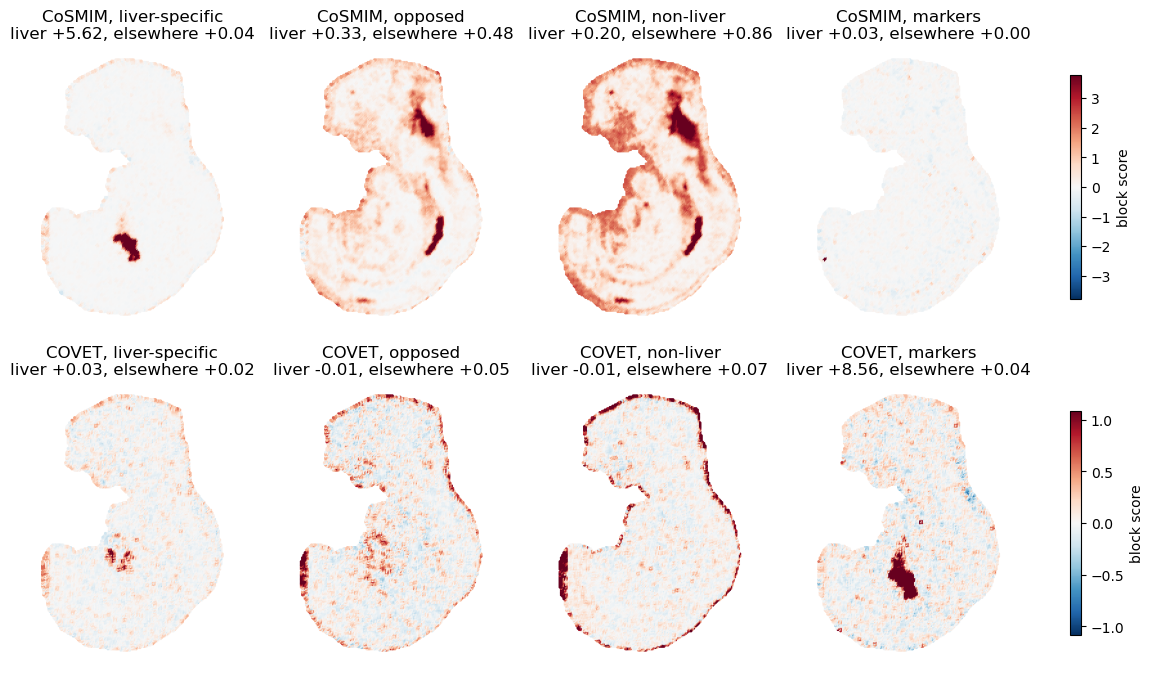

In [11]:
n_cells = a1.n_obs
pairs = {k: [(run_genes.index(a), run_genes.index(b)) for a, b in zip(*[np.array(genes)[t] for t in np.triu_indices(len(genes), 1)])]
         for k, genes in BLOCKS.items()}
raw = {k: np.zeros(n_cells) for k in BLOCKS}
diag_sum = np.zeros(len(run_genes))
for start in range(0, n_cells, 1500):
    sigma = niche_sigma(a1.obsm["cosmim"][start:start + 1500])
    diag_sum += np.einsum("nii->i", sigma)
    for k, pl in pairs.items():
        raw[k][start:start + 1500] = np.mean([sigma[:, i, j] for i, j in pl], axis=0)
scale = np.sqrt(np.clip(diag_sum / n_cells, 1e-12, None))
scores = {("CoSMIM", k): raw[k] / np.mean([scale[i] * scale[j] for i, j in pl]) for k, pl in pairs.items()}

cov_pairs = {k: [(panel_genes.index(a), panel_genes.index(b)) for a, b in zip(*[np.array(genes)[t] for t in np.triu_indices(len(genes), 1)])]
             for k, genes in BLOCKS.items()}
cov_scale = np.sqrt(np.clip(np.einsum("nii->i", covet_cells).astype(np.float64) / n_cells, 1e-12, None))
for k, pl in cov_pairs.items():
    v = np.mean([covet_cells[:, i, j] for i, j in pl], axis=0)
    scores[("COVET", k)] = v / np.mean([cov_scale[i] * cov_scale[j] for i, j in pl])

names = {"core": "liver-specific", "anti": "opposed", "nonspec": "non-liver", "marker": "markers"}
xy = a1.obsm["spatial"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, method in enumerate(["CoSMIM", "COVET"]):
    lim = np.nanpercentile(np.abs(np.concatenate([scores[(method, k)] for k in BLOCKS])), 99)
    for ax, k in zip(axes[row], BLOCKS):
        v = scores[(method, k)]
        im = ax.scatter(xy[:, 0], xy[:, 1], c=v, s=1, cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set_title(f"{method}, {names[k]}\nliver {np.nanmean(v[liver]):+.2f}, "
                     f"elsewhere {np.nanmean(v[~liver]):+.2f}")
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
    fig.colorbar(im, ax=axes[row], shrink=0.8, label="block score")
plt.show()